In [6]:
import cv2 as cv
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from pylab import mpl
from scipy.stats import mode
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
# import hydra
import torch
from PIL import Image


if torch.cuda.is_available():
    device = torch.device("cuda")
    print(f"Using GPU: {torch.cuda.get_device_name(0)}")
else:
    device = torch.device("cpu")
    print("CUDA not found, using CPU.")
"""""" 

Using GPU: NVIDIA GeForce RTX 5080


c:\Users\E114\AppData\Local\Programs\Python\Python39\lib\site-packages\torch\cuda\__init__.py:235: UserWarning: 
NVIDIA GeForce RTX 5080 with CUDA capability sm_120 is not compatible with the current PyTorch installation.
The current PyTorch install supports CUDA capabilities sm_50 sm_60 sm_61 sm_70 sm_75 sm_80 sm_86 sm_90.
If you want to use the NVIDIA GeForce RTX 5080 GPU with PyTorch, please check the instructions at https://pytorch.org/get-started/locally/

  warnings.warn(


''

In [2]:
import cv2 as cv
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from pylab import mpl
from scipy.stats import mode
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
# import hydra
import torch
from PIL import Image


if torch.cuda.is_available():
    device = torch.device("cuda")
    print(f"Using GPU: {torch.cuda.get_device_name(0)}")
else:
    device = torch.device("cpu")
    print("CUDA not found, using CPU.")
"""""" 

Using GPU: NVIDIA GeForce RTX 5080


c:\Users\E114\AppData\Local\Programs\Python\Python39\lib\site-packages\torch\cuda\__init__.py:235: UserWarning: 
NVIDIA GeForce RTX 5080 with CUDA capability sm_120 is not compatible with the current PyTorch installation.
The current PyTorch install supports CUDA capabilities sm_50 sm_60 sm_61 sm_70 sm_75 sm_80 sm_86 sm_90.
If you want to use the NVIDIA GeForce RTX 5080 GPU with PyTorch, please check the instructions at https://pytorch.org/get-started/locally/

  warnings.warn(


''

In [8]:
#parameters

#camera parameters
FOCAL_POINT = 700.0 #cm
TE = 100#amount of calibration images for each distance
F = 4.0 #cm 1.6 for sony ,  4.0 for cannon
D1 = F/13.0 #cm   2.8 for sony, 13.0 for cannon
D2 = F/22.0 #cm   5.6 for sony, 22.0 for cannon
S =  (FOCAL_POINT*F)/(FOCAL_POINT-F) #cm when focus is at FOCAL_POINT cm
M2 = -((D2*S)/np.sqrt(8))
C2 = (-M2)*((1/F)-(1/S))
FRACTION = (D1/D2)**2
IMG_SIZE = (2033, 1520) #(1824,1216) #for sony (2304,1536)  ,for canon (1824,1216)
# IMG_SIZE = (1536,2048)
SHOW_SIZE = (IMG_SIZE[0]//2,IMG_SIZE[1]//2) # for showing

#data processing parameters
SEGMENT = list()
VLP = list()  # for checking img status between different functions
BOX = list()  # for storing data to generate box graph
SMALLER = "/R"   # for smaller aperture, e.g. f/13.0
LARGER = "/L"    # for larger aperture   e.g. f/22.0
POSITION_START = 0
POSITION_END = 13
CAL_HEAD = "./datas/Training_dataset_Focus700cm_f13.0_f22.0/"
G_SELECT = 2 # 2 calculate larger aperture's blur, 1 for smaller aperture
NEED_SEG = False
BASE = 100   # base distance for training
PARA = 50   # distance between two training sets
PROCESS_STORAGE = "./final/"#CAL_HEAD[:-1]+"_process/"
BLUR_STORAGE = CAL_HEAD[:-1]+"_blur/"
BLUR_STORAGE_F = CAL_HEAD[:-1]+"_blur_f/"
RESULT = "./result/Dataset_Focus75cm_f1.8_f22/" 
KER =  19 #for canon : max = 38 , middle = 19 ; for sony: max = 48 , middle = 24 , min = 12
CLAHE = cv.createCLAHE(clipLimit=2.0, tileGridSize=(64,64)) #original clipLimit=2.0, tileGridSize=(70,70)
# THRESHOLD = 3000000.0  #ker = 7
THRESHOLD = 3000000.0  # ker = 5
REC = False
REC2 = False
REC3 = False
# load images' name
def load_img():
    global R,L,MASK,MASK_HEAD

    MASK_HEAD = CAL_HEAD[:-1]+"_mask/"
    head = os.listdir(CAL_HEAD)
    head = sorted(head)
    l_place = [CAL_HEAD+i+LARGER for i in head[POSITION_START:POSITION_END]]
    r_place = [CAL_HEAD+i+SMALLER for i in head[POSITION_START:POSITION_END]]
    fileL = [sorted(os.listdir(place)) for place in l_place]
    fileR = [sorted(os.listdir(place)) for place in r_place]
    fileL = [[f for f in files if f] for files in fileL]
    fileR = [[f for f in files if f] for files in fileR]
    R = [[top+"/"+file for file in img] for img,top in  zip(fileR,r_place)]
    L = [[top+"/"+file for file in img] for img,top in  zip(fileL,l_place)]
    MASK = [np.load(f"{MASK_HEAD}T{i}.npy") for i in range((POSITION_START+1),POSITION_END+1)] if os.path.exists(MASK_HEAD) else None

# load_img()
JUMPER = 0

In [4]:
# Tools 

def mouse(event, x, y, flags, param):
    if event == cv.EVENT_LBUTTONDOWN:
        print(f"Left button clicked at ({x}, {y})")
        print(f"VLP(laplacian): {VLP[0][y,x]} VLP2(difference): {VLP[0][y,x]}")

def showing(img,cnt,flag,img_name="",floder_name=""): 
    cv.namedWindow(f"showing_{cnt}",cv.WINDOW_NORMAL)
    cv.resizeWindow(f"showing_{cnt}",SHOW_SIZE[0],SHOW_SIZE[1])
    store = None
    if flag == 1:
        show = img.copy()
        # show = cv.normalize(show, None, 0, 255, cv.NORM_MINMAX)
        show = show.astype(np.uint8)
        cv.imshow(f"showing_{cnt}",show)
        store = show.copy()
    elif flag == 2:
        show = img.copy()
        show = show.astype(np.uint8)
        #VLP.append(show.copy()) 
        show[show > 0] = 255
        show[np.isnan(show)] = 0

        show = cv.cvtColor(show, cv.COLOR_GRAY2BGR)
        show[(img <= 0.0)] = [255,255,255]
        show[(img <=0.1) & (img>0.0)] = [0,0,255]
        show[(img >0.1)&(img<=0.12)] = [0,255,0] 
        show[img > 0.12] = [0,255,0]



        # show = cv.normalize(show, None, 0, 255, cv.NORM_MINMAX)
        cv.imshow(f"showing_{cnt}",show)
        cv.setMouseCallback(f"showing_{cnt}", mouse)
        store = show
    key = cv.waitKey(0)
    if key == 27 or key == ord('q'): #ESC
        cv.destroyAllWindows()
        return False
    elif key == ord('s'): #SPACE
        if not os.path.exists(PROCESS_STORAGE):
            os.makedirs(PROCESS_STORAGE)
        if floder_name != "":
            floder_name = floder_name + "/"
            if not os.path.exists(PROCESS_STORAGE+floder_name):
                os.makedirs(PROCESS_STORAGE+floder_name)
        if flag == 1:
            cv.imwrite(f"{PROCESS_STORAGE}{floder_name}{img_name}_{cnt}.jpg",store)
        elif flag == 2:
            cv.imwrite(f"{PROCESS_STORAGE}{floder_name}{img_name}_{cnt}.jpg",store)
        cv.destroyAllWindows()
        return True
    cv.destroyAllWindows()
    return True

def showing2(img,cnt,flag):
    cv.namedWindow(f"showing1_{cnt}",cv.WINDOW_NORMAL)
    cv.namedWindow(f"showing2_{cnt}",cv.WINDOW_NORMAL)
    cv.resizeWindow(f"showing1_{cnt}",SHOW_SIZE[0],SHOW_SIZE[1])
    cv.resizeWindow(f"showing2_{cnt}",SHOW_SIZE[0],SHOW_SIZE[1])
    cv.moveWindow(f"showing1_{cnt}",0,0)
    cv.moveWindow(f"showing2_{cnt}",SHOW_SIZE[0]+100,0)
    show_res = None
    if flag == 1:
        show1 = img[0].copy()
        show2 = img[1].copy()
        show1 = cv.normalize(show1, None, 0, 255, cv.NORM_MINMAX)
        show2 = cv.normalize(show2, None, 0, 255, cv.NORM_MINMAX)
        cv.imshow(f"showing1_{cnt}",show1)
        cv.imshow(f"showing2_{cnt}",show2)
    elif flag == 2:
        show1 = img[0].copy().astype(np.uint8)*255
        show2 = cv.resize(img[1].copy(),IMG_SIZE)
        
        show1 = cv.cvtColor(show1, cv.COLOR_GRAY2BGR)
        show = cv.addWeighted(show1, 0.5, show2, 0.5, 0)
        cv.imshow(f"showing1_{cnt}",show)
        show_res = show.copy()
    key = cv.waitKey(0)
    if key == 27: #ESC
        cv.destroyAllWindows()
        return False
    elif key == ord('s'): #SPACE
        pass
    cv.destroyAllWindows()
    return show_res


def find_intersection(p1,p2,p3,p4):
    A1 = np.float64(p2[1] - p1[1])
    B1 = np.float64(p1[0] - p2[0])
    C1 = A1 * np.float64(p1[0]) + B1 * np.float64(p1[1])

    A2 = np.float64(p4[1] - p3[1])
    B2 = np.float64(p3[0] - p4[0])
    C2 = A2 * np.float64(p3[0]) + B2 * np.float64(p3[1])

    determinant = A1 * B2 - A2 * B1

    if determinant == 0:
        return None  # 平行或重合
    else:
        x = (B2 * C1 - B1 * C2) / determinant
        y = (A1 * C2 - A2 * C1) / determinant
        return int(x), int(y)
def read_cr2(file):
    with Image.open(file) as raw:
        rgb = raw.convert("RGB")
        rgb = np.array(rgb)
        bgr = cv.cvtColor(rgb, cv.COLOR_RGB2BGR)
        return bgr
    
def reset_txt(file):
    with open(file, 'w') as f:
        f.write('')

In [6]:
#functions

BOX.clear()
VLP.clear()
clicks = []

def mouse_callback(event, x, y, flags, param): #check the value of lp
    global VLG,clicks
    if event == cv.EVENT_LBUTTONDOWN:
        print("Y:", y," X: ",x)
        clicks.append((x, y))
        print('lg value:', VLG[y, x])
    if len(clicks) == 4:
        x_cor = [p[0] for p in clicks]
        y_cor = [p[1] for p in clicks]
        x_min,x_max = min(x_cor),max(x_cor)
        y_min,y_max = min(y_cor),max(y_cor)

        vlg_region = VLG[y_min:y_max+1,x_min:x_max+1]
        vlg_region = vlg_region[vlg_region != 0]
        mean_v = np.mean(vlg_region)
        print("VLG region : ",mean_v)
        print("Distance : ",f(mean_v,*param[0]))

        show = param[1].copy()
        show = np.array(show,dtype=np.float64)
        show = cv.normalize(show, None, alpha=0, beta=255, norm_type=cv.NORM_MINMAX, dtype=cv.CV_8U)
        show = cv.cvtColor(show,cv.COLOR_GRAY2BGR)
        show = cv.rectangle(show,(x_min,y_min,x_max-x_min,y_max-y_min),(0,255,0),2)
        cv.imshow("cut",show)
        clicks = []

def compute(r,l,flag = 0,seg = None):
    global SEGMENT
    time_pass = 0
    # if flag == 1:
    #     tt = cv.getTickCount()
    #     sa_graph = cv.cvtColor(l,cv.COLOR_BGR2RGB)
    #     sa_graph = cv.resize(sa_graph,IMG_SIZE,interpolation=cv.INTER_AREA)
        

    #     mask_generator = SAM2AutomaticMaskGenerator(SAM2,8,64,0.8,0.85,box_nms_thresh=0.8) #載入mask產生器

    #     masks = mask_generator.generate(sa_graph) #產生mask
    #     SEGMENT = masks
    #     print("SEGMENTATION DONE")
    #     time_pass = (cv.getTickCount() - tt) / cv.getTickFrequency()
    #     SEGMENT = sorted(SEGMENT, key=(lambda x: x['area']), reverse=True)

    # resize
    r = cv.resize(r,IMG_SIZE ,interpolation=cv.INTER_AREA)
    l = cv.resize(l,IMG_SIZE ,interpolation=cv.INTER_AREA)

    
    # r = cv.cvtColor(r,cv.COLOR_BGR2HSV_FULL)
    # l = cv.cvtColor(l,cv.COLOR_BGR2HSV_FULL)

    #brightness adjustment
    if flag == 2:
        SEGMENT = []
        unique = np.unique(seg)
        unique = unique.astype(np.uint8)
        unique = unique[unique != 0]
        for i in unique:
            one_seg = np.where(seg == i,1,0)
            one_seg = one_seg.astype(np.uint8)
            SEGMENT.append({"segmentation":one_seg,"area":np.sum(one_seg)})



    # for m in SEGMENT:
    #     r_temp = np.where(m['segmentation'] != 0,r[:,:,2],0)
    #     l_temp = np.where(m['segmentation'] != 0,l[:,:,2],0)
        
    #     brightnessR = np.mean(r_temp)
    #     brightnessL = np.mean(l_temp)

    #     alphar = brightnessR/brightnessL
    #     print("brightnessR : ",brightnessR ," brightnessL : ",brightnessL)
    #     print("brightness ration : ",alphar)
        
    #     # $ brightness adjust core

    #     l_temp = cv.convertScaleAbs(l_temp, alpha=alphar, beta=0)
        

    #     r[:,:,2] = np.where(m['segmentation'] != 0,r_temp,r[:,:,2])
    #     l[:,:,2] = np.where(m['segmentation'] != 0,l_temp,l[:,:,2])

    # r = cv.cvtColor(r,cv.COLOR_HSV2BGR_FULL)
    # l = cv.cvtColor(l,cv.COLOR_HSV2BGR_FULL)
    
    
    r = cv.cvtColor(r,cv.COLOR_BGR2GRAY)
    l = cv.cvtColor(l,cv.COLOR_BGR2GRAY)
    
    for m in SEGMENT:
        r_temp = np.where(m['segmentation'] != 0,r,0)
        l_temp = np.where(m['segmentation'] != 0,l,0)
        
        brightnessR = np.mean(r_temp)
        brightnessL = np.mean(l_temp)

        alphar = brightnessR/brightnessL
        # print("brightnessR : ",brightnessR ," brightnessL : ",brightnessL)
        # print("brightness ration : ",alphar)
        
        # $ brightness adjust core

        l_temp = cv.convertScaleAbs(l_temp, alpha=alphar, beta=0)
        

        r = np.where(m['segmentation'] != 0,r_temp,r)
        l = np.where(m['segmentation'] != 0,l_temp,l)

    # showing2([r,l],0,1)

    r = CLAHE.apply(r)
    l = CLAHE.apply(l)

    r = np.int16(r)
    l = np.int16(l)
    # gaussian and laplacian
    # vector = cv.getGaussianKernel(5,0.5)
    # kernel = vector @ vector.T
    # Gr = cv.filter2D(r,-1,kernel)
    # Gl = cv.filter2D(l,-1,kernel)
    

    k_size = 7
    scale = 2
    
    Lp = None
    if G_SELECT == 1:#result will be r's blur degree
        Lp = cv.Laplacian(l,cv.CV_64F,ksize=k_size,scale=scale)
    elif G_SELECT == 2:#result will be l's blur degree
        Lp = cv.Laplacian(r,cv.CV_64F,ksize=k_size,scale=scale)


    dif = l-r
    dif = np.float64(dif)**2
    # if(temp.min()<0):
    #     print("HAS NEGATIVE VALUE")
    #     print(temp.min())
    #     print("==========================")
    Lp = Lp**2
    
    if flag == 1:
        return dif,Lp,time_pass
    if flag == 2:
        return dif,Lp,1
   
def sliding_window_sum(mask,target):
    # 獲取mask的形狀
    rows, cols = mask.shape
    
    # 初始化結果矩陣
    out_rows = (rows - KER) // KER + 1
    out_cols = (cols - KER) // KER + 1
    
    # 初始化結果矩陣
    result = np.zeros((out_rows, out_cols), dtype=object)
    
    # 遍歷mask
    for i in range(0, rows - KER + 1, KER):
        for j in range(0, cols - KER + 1, KER):
            # 獲取當前窗口
            window = mask[i:i + KER, j:j + KER]
            target_window = target[i:i + KER, j:j + KER]

            # 找出窗口內的所有區域
            unique_regions = np.unique(window)
            unique_regions = unique_regions[unique_regions != 0]
            unique_regions = unique_regions[~np.isnan(unique_regions)]
            # 初始化當前窗口的結果
            window_result = {}
            
            # 計算每個區域的總和
            for region in unique_regions:
                # show_mask = np.zeros_like(mask)
                # mask_temp = np.where(window == region, 1, 0)
                # show_mask[i:i + KER, j:j + KER] = mask_temp
                # show_mask = cv.cvtColor(show_mask.astype(np.uint8), cv.COLOR_GRAY2BGR)
                # show_mask *= 255
                # show_window = cv.addWeighted(cv.resize(VLP[0],IMG_SIZE), 0.5, show_mask, 0.5, 0)
                # showing(show_window,region,1)
                window_result[region] = np.nansum(target_window[window == region])
            # 儲存結果
            result[i // KER, j // KER] = window_result
            
    return result

def compute_blurness(sum_dif,sum_Lp,mask,record = False,distance_para = None):
    temp_dif = None
    temp_Lp = None
    range_dis = None
    blurness = np.zeros_like(sum_dif)
    mean = []
    if record:
        temp_dif = np.zeros_like(sum_dif)
        temp_Lp = np.zeros_like(sum_Lp)
    if distance_para is not None:
        range_dis = np.zeros_like(sum_dif)
    for m in mask:
        for i in range(len(sum_dif)):
            for j in range(len(sum_dif[0])):
                if m in sum_dif[i,j] and sum_Lp[i,j][m] != 0 and sum_Lp[i,j][m] != np.nan and sum_dif[i,j][m] != np.nan:
                    if record:
                        temp_dif[i,j] = sum_dif[i,j][m]
                        temp_Lp[i,j] = sum_Lp[i,j][m]
                    mean.append( sum_Lp[i,j][m])
                    G = np.sqrt(np.divide((16*sum_dif[i,j][m]),sum_Lp[i,j][m]))
                    parameter = ((FRACTION-1) if G_SELECT==2 else (1-(1/FRACTION)))
                    blurness[i,j] = np.sqrt(np.divide(G,parameter))
                    if distance_para is not None:
                        range_dis[i,j] = f(blurness[i,j],*distance_para)
                else:
                    blurness[i,j] = np.nan
                    if record:
                        temp_dif[i,j] = np.nan
                        temp_Lp[i,j] = np.nan
                    if distance_para is not None:
                        range_dis[i,j] = np.nan
    mean_lp = np.nanmean(mean)

    if distance_para is None:
        return blurness,temp_dif,temp_Lp
    else:
        return blurness,range_dis

def train():
    # global THRESHOLD
    distance = [BASE + PARA*i for i in range(POSITION_END-POSITION_START)]
    real = [BASE + PARA*time for time in range(POSITION_END-POSITION_START) for _ in range(TE) ]
    totalBlurness = []

    count = 1
    lp_seg = None
    for rs,ls,seg in zip(R,L,MASK):
        print(f"Calibrating {(count//TE)+1} group")
        seg = cv.resize(seg,IMG_SIZE)
        # print("Area : ",cv.countNonZero(seg))
        for r_name in rs:
            r = None
            if r_name.endswith(".CR2"):
                r = read_cr2(r_name)
            else:
                r = cv.imread(r_name)
            for l_name in ls:
                # read image
                l = None
                if l_name.endswith(".CR2"):
                    l = read_cr2(l_name)
                else:
                    l = cv.imread(l_name)
                # compute laplacian and difference value
                dif,Lp,_ = compute(r,l,2,seg=seg)
                #seg_show = cv.addWeighted(cv.resize(r, seg.shape[::-1]), 0.5, cv.cvtColor(seg.astype(np.uint8), cv.COLOR_GRAY2BGR)*255, 0.5, 0)
                # if np.sum(seg) <= 40000000.0:
                #     THRESHOLD = 500000.0
                # else:
                #     THRESHOLD = 3000000.0
                # print("SUM : ",np.sum(seg))
                # print("THRESHOLD : ",THRESHOLD)
                lp_seg = np.where(Lp<=THRESHOLD,0,seg)  #edge after method

                dif = np.where(seg != 0,dif,np.nan)
                Lp = np.where(seg != 0,Lp,np.nan)
                
                #VLP.append(lp_seg.copy())
                # showing(lp_seg,count,2,img_name="mask_",floder_name="mask")
                #showing(dif,count,2)
                # print("=====================================")
                # print("Mean of difference : ",np.nanmean(dif))
                # print("=====================================")
                
                #VLP.clear()
                sum_dif = sliding_window_sum(seg,dif)
                sum_Lp = sliding_window_sum(seg,Lp)

            
                blurness = np.zeros_like(sum_dif)
                vals = np.unique(seg)
                vals = vals[vals != 0]

                blurness,temp_dif,temp_Lp = compute_blurness(sum_dif,sum_Lp,vals,record=REC)
                blurness = np.array(blurness,dtype=np.float64)


                if REC2:  # for recording convoluted blurness
                    if os.path.isdir(BLUR_STORAGE) == False:
                        os.mkdir(BLUR_STORAGE)
                    if os.path.isdir(f"{BLUR_STORAGE}T{((count-1)//TE)+1}") == False:
                        os.mkdir(f"{BLUR_STORAGE}T{((count-1)//TE)+1}")
                    np.save(f"{BLUR_STORAGE}T{((count-1)//TE)+1}/{str(count).zfill(4)}.npy",blurness)
                
                if lp_seg is not None:
                    blurness = np.repeat(np.repeat(blurness,KER,axis=0),KER,axis=1)
                    blurness[lp_seg == 0] = np.nan
                    # if count // TE >= 5:
                    #     temp_dif = np.repeat(np.repeat(temp_dif,KER,axis=0),KER,axis=1)
                    #     temp_Lp = np.repeat(np.repeat(temp_Lp,KER,axis=0),KER,axis=1)
                    #     VLP.append(temp_Lp.copy())
                    #     VLP.append(temp_dif.copy())
                    #     showing(blurness,count,2,img_name="blurness",floder_name="blur")

                if REC3:  # for recording full size blurness
                    if os.path.isdir(BLUR_STORAGE_F) == False:
                        os.mkdir(BLUR_STORAGE_F)
                    if os.path.isdir(f"{BLUR_STORAGE_F}T{((count-1)//TE)+1}") == False:
                        os.mkdir(f"{BLUR_STORAGE_F}T{((count-1)//TE)+1}")
                    np.save(f"{BLUR_STORAGE_F}T{((count-1)//TE)+1}/{str(count).zfill(4)}.npy",blurness)

                blurness = blurness[np.isnan(blurness) == False]
                

                # $
                if temp_dif is not None:
                    # temp_Lp = np.repeat(np.repeat(temp_Lp,KER,axis=0),KER,axis=1)
                    # temp_dif = np.repeat(np.repeat(temp_dif,KER,axis=0),KER,axis=1)
                    # temp_Lp[lp_seg == 0.0] = 0.0
                    # temp_dif[lp_seg == 0.0] = 0.0
                    if os.path.isdir(CAL_HEAD[:-1]+"_detail") == False:
                        os.mkdir(CAL_HEAD[:-1]+"_detail")
                        os.mkdir(CAL_HEAD[:-1]+"_detail/lap")
                        os.mkdir(CAL_HEAD[:-1]+"_detail/dif")
                    np.save(f"{CAL_HEAD[:-1]}_detail/lap/T{count}.npy",temp_Lp)
                    np.save(f"{CAL_HEAD[:-1]}_detail/dif/T{count}.npy",temp_dif)

                # print(f"Length of blurness : {len(blurness)}")

                smooth_blurness = np.nanmean(blurness)

                #if smooth_o2>0.1:
                #    smooth_o2 = np.nan

                totalBlurness.append(smooth_blurness)
                print(f"Done {count%TE} .")
                count += 1
            #     break
            # break
    mean_of_all_blurness = dict()
    res = list()
    blurness_distance = {totalBlurness[i]:real[i] for i in range(len(totalBlurness))}
    print(blurness_distance)
    index = 0
    for _ in range(POSITION_END):
        res.append(totalBlurness[index:(index+TE)])
        index += TE


    for dist,part_blurness in zip(distance,res):
        print(part_blurness)
        blurness_temp = np.array(part_blurness,dtype=np.float64)
        mean = np.nanmean(blurness_temp)
        mean_of_all_blurness.update({mean:dist})
    
    print(mean_of_all_blurness)
    compute_model(mean_of_all_blurness,blurness_distance)

    plt.figure(figsize=(14,5))
    plt.subplot(1,2,2)
    plt.plot(totalBlurness)
    plt.xlabel("ID")
    plt.xticks(np.arange(0,len(totalBlurness)+1,TE))
    plt.ylabel("Bluryness")
    for x in range(0,len(totalBlurness),TE):
        plt.axvline(x,color='r',linestyle='--')

    plt.title("Bluryness")
    
    for i,data in enumerate(res):
        print(f"DIS{distance[i]} : {np.std(data)}")
    
    f = open("calibrate.txt","+a")
    for i in res:
       f.write(str(np.mean(i))+"\n")
    f.write("\n")
    f.close()
    plt.show()
    # plt.savefig(f'{RESULT}Blurriness.png')
# ==========================================
# 1. 定義新的物理模型函數 (取代原本單一的 f)
# ==========================================
def inverse_func(x, a, b, c):
    """反比模型: y = a / (x + b) + c (符合光學模糊物理特性)"""
    return a / (x + b) + c

def power_func(x, a, b, c):
    """冪函數模型: y = a * x^b + c"""
    return a * np.power(x, b) + c

# ==========================================
# 2. 修改後的計算與繪圖函數
# ==========================================
def compute_model(table, table2):
    # --- A. 數據整理 ---
    # 將字典轉為 numpy array
    x_mean = np.array(list(table.keys()))
    y_mean = np.array(list(table.values()))
    
    x_raw = np.array(list(table2.keys()))
    y_raw = np.array(list(table2.values()))

    # 重要：對平均值的 X 進行排序 (為了讓擬合線條平滑連續，解決你原本線條斷掉的問題)
    sort_idx = np.argsort(x_mean)
    x_mean_sorted = x_mean[sort_idx]
    y_mean_sorted = y_mean[sort_idx]

    # 建立平滑的 X 軸 (用於畫線，範圍涵蓋數據的最小到最大值)
    x_smooth = np.linspace(min(x_raw), max(x_raw), 500)

    plt.figure(figsize=(10, 6))
    
    # --- B. 畫出數據點 ---
    # 畫出所有原始數據 (綠色半透明)
    plt.scatter(x_raw, y_raw, color='green', label="Raw Data", alpha=0.2, s=20)
    # 畫出平均數據 (紅色實點，用於訓練)
    plt.scatter(x_mean, y_mean, color='red', label="Smoothed Data (Mean)", s=50, zorder=5)

    print("\n=== Model Fitting Results ===")

    # --- C. 擬合各種模型 ---
    
    # 1. 反比模型 (Inverse) - 最推薦
    try:
        # p0 是初始猜測值，避免擬合發散
        popt_inv, _ = curve_fit(inverse_func, x_mean_sorted, y_mean_sorted, p0=[1000, 0.01, 0], maxfev=10000)
        plt.plot(x_smooth, inverse_func(x_smooth, *popt_inv), color='blue', linewidth=2.5, label='Inverse (1/x)')
        print(f"[Inverse] a={popt_inv[0]:.2f}, b={popt_inv[1]:.4f}, c={popt_inv[2]:.2f}")
    except Exception as e:
        print(f"[Inverse] Fit failed: {e}")

    # 2. 冪函數模型 (Power)
    try:
        popt_pow, _ = curve_fit(power_func, x_mean_sorted, y_mean_sorted, p0=[100, -1, 0], maxfev=10000)
        plt.plot(x_smooth, power_func(x_smooth, *popt_pow), color='purple', linestyle='--', linewidth=2, label='Power (x^b)')
        print(f"[Power]   a={popt_pow[0]:.2f}, b={popt_pow[1]:.4f}, c={popt_pow[2]:.2f}")
    except:
        print("[Power]   Fit failed")

    # 3. 二次多項式 (Quadratic) - 你原本用的
    # coef_quad = np.polyfit(x_mean_sorted, y_mean_sorted, 2)
    # plt.plot(x_smooth, np.poly1d(coef_quad)(x_smooth), color='orange', linestyle='-.', label='Quadratic')

    # 4. 三次多項式 (Cubic)
    # coef_cubic = np.polyfit(x_mean_sorted, y_mean_sorted, 3)
    # plt.plot(x_smooth, np.poly1d(coef_cubic)(x_smooth), color='gray', linestyle=':', alpha=0.7, label='Cubic')

    # --- D. 圖表設定 ---
    plt.title("Relationship between blur and distance (Model Comparison)")
    plt.xlabel("Blurriness")
    plt.ylabel("Distance (cm)")
    
    # 自動根據數據設定 Y 軸範圍，不寫死
    # plt.ylim(BASE-PARA, BASE + POSITION_END * PARA) # 如果原本的變數還在，也可以用這行
    plt.ylim(min(y_raw)*0.9, max(y_raw)*1.1)

    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()
    # plt.savefig(f'{RESULT}Model.png')


def main(r_name,l_name,mask_save_num = 0,seg_mask = None,round_idx = 0,oblique = False,seg_size = None): # mask_save_num is the para to specify call from get_shape() or exp()
    global SEGMENT
    
    para = [[58548842.89336719, -17672175.18318926, 1778393.29995472, -59512.70877175 ]]
    r,l = None,None
    #read image
    if r_name.endswith(".CR2"):
        r = read_cr2(r_name)
    else:
        r = cv.imread(r_name)
    if l_name.endswith(".CR2"):
        l = read_cr2(l_name)
    else:
        l = cv.imread(l_name)
    #adjust segmentation mask range
    if seg_size != None:
        print(np.unique(seg_mask))
        seg_temp = np.where(seg_mask != 1,seg_mask,0)
        seg_mask = np.where(seg_mask == 1,seg_mask,0)
        seg_mask = seg_mask.astype(np.uint8)

        current_area = cv.countNonZero(seg_mask)
        if current_area > 0:
            ksize = int(np.sqrt(current_area*abs(seg_size)))
            print("current ksize : ",ksize)
            if ksize < 3:
                ksize = 3
            if ksize % 2 == 0:
                ksize += 1
            kernel = np.ones((ksize,ksize),np.uint8)

            if(seg_size >0):
                seg_mask = cv.dilate(seg_mask,kernel,iterations=1)
            elif(seg_size<0):
                seg_mask = cv.erode(seg_mask,kernel,iterations=1)
                
        seg_mask = np.where(seg_mask != 1,seg_temp,seg_mask)
        # img_w = showing2([seg_mask,l],0,2) 
        # if os.path.isdir(RESULT) == False:
        #     os.mkdir(RESULT)
        # if os.path.isdir(f"{RESULT}T{round_idx}") == False:
        #     os.mkdir(f"{RESULT}T{round_idx}")
        # cv.imwrite(f"{RESULT}T{round_idx}/{seg_size}.jpg",img_w)


    tt = cv.getTickCount()
    dif,Lp,seg_time = compute(r,l,flag=(2 if mask_save_num == 0 else 1),seg=seg_mask)
    other_time = ((cv.getTickCount() - tt) / cv.getTickFrequency()) - seg_time
    print("Segmetation cost: ",seg_time," sec")

    final_distance = np.zeros_like(dif)
    used = np.zeros_like(dif).astype(bool)
    
    count = 1
    real_distance = [[25.0],
                     [56.0],
                     [103.0],
                     [33.0],
                     [64.0],
                     [97.0],
                     [41.0],
                     [73.0],
                     [88.0]
                     ]
    np_save = np.zeros_like(dif)
    
    masks = np.zeros_like(dif).astype(np.uint8)
    size_of_mask = list()
    
    for mask in SEGMENT:
        
        tt = cv.getTickCount()
        window_size = mask['segmentation']
        window_size = window_size.astype(np.uint8)
        opening_kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (5, 5))
        window_size = cv.morphologyEx(window_size, cv.MORPH_OPEN, opening_kernel,iterations=2).astype(bool)
        dif_shape = dif.shape
        window_shape = window_size.shape
        repeat_y = dif_shape[0] // window_shape[0]
        repeat_x = dif_shape[1] // window_shape[1]
        window_size = np.repeat(np.repeat(window_size,repeat_y,axis=0),repeat_x,axis=1) #expand window_size to the same size of dif

        if mask_save_num != 0:
            print(f"Area of {mask_save_num} : ",mask['area'])
            box = mask['bbox']
            l_temp = cv.resize(l,IMG_SIZE)
            l_temp[window_size] = [0,0,0]
            #l_temp = cv.rectangle(l_temp,(box[0],box[1]),(box[0]+box[2],box[1]+box[3]),(0,255,0),2)
            cv.namedWindow("cut",cv.WINDOW_NORMAL)
            cv.resizeWindow("cut", 1440,720)
            cv.imshow("cut",l_temp)

            button = cv.waitKey(0)
            if button == ord('s'):
                np_save[window_size] = count#real_distance[mask_save_num-1][count-1]
                print("SAVE DONE")
                count += 1
            elif button == ord('q'):
                cv.destroyAllWindows()
                break
            cv.destroyAllWindows()
            continue
        if np.all(np.logical_xor(np.logical_and(window_size,used),window_size) == False): #check if the window is already used
            continue
        size_of_mask.append(mask['area'])
        masks[window_size] = count
        count +=1
        used[window_size] = True
        
    
    # save mask
    if np_save.max() != 0: 
        if os.path.isdir(MASK_HEAD) == False:
            os.mkdir(MASK_HEAD)
        np.save(f'{MASK_HEAD}T{mask_save_num}.npy',np_save)
        return
    
    other_time += ((cv.getTickCount() - tt) / cv.getTickFrequency())

    #integrate with laplacian value > x 
    #edge_of_img = None
    edge_of_img = np.where(Lp<THRESHOLD,0,masks)

    uni_mask = np.unique(masks)
    uni_mask = uni_mask[uni_mask!=0]
    sum_dif = sliding_window_sum(masks,dif)
    sum_Lp = sliding_window_sum(masks,Lp)
    current_para = para[0]
    
    for m in uni_mask:

        tt = cv.getTickCount()
        pos = np.where(masks==m)
        pos = np.array(pos)

        #one_mask = np.zeros_like(masks)
        #one_mask[pos[0],pos[1]] = 1
    
        blurness,range_dis = compute_blurness(sum_dif,sum_Lp,[m],record=False,distance_para=current_para)
                
        if oblique and range_dis.max() != 0.0:

            range_dis[(range_dis <= 0.0)] = 0.0  # original <0 is 0
            range_dis[(range_dis >= 120.0)] = 120.0 # original >= 120 is 120
            resize_dis = np.repeat(np.repeat(range_dis,KER,axis=0),KER,axis=1)
            #print(f"Distance : {resize_dis[right_bottom[0][1],right_bottom[0][0]]} {resize_dis[left_bottom[0][1],left_bottom[0][0]]} {resize_dis[right_top[0][1],right_top[0][0]]} {resize_dis[left_top[0][1],left_top[0][0]]} {resize_dis[center[1],center[0]]}")
            show,x_coe,y_coe,score= model_3d(resize_dis,edge_of_img,one_mask,round_idx)
            print(f"ROUND {round_idx} : {x_coe} , {y_coe} , {score}")
            show[(show<0.0)] = 0.0
            #result = np.zeros_like(masks).astype(np.float64)
            #for i in range(len(pos[0])):
            #    result[pos[0][i],pos[1][i]] = show[int(pos[0][i]/KER),int(pos[1][i]/KER)]
            #if os.path.isdir(MASK_HEAD[:-1]+"_imgs/") == False:
            #    os.mkdir(MASK_HEAD[:-1]+"_imgs/")
            
            result = show.copy()

            #precision 
            temp_mask = one_mask.astype(np.uint8)
            temp_mask = cv.dilate(temp_mask, np.ones((3,3),np.uint8), iterations = 2)
            temp_mask = cv.erode(temp_mask, np.ones((3,3),np.uint8), iterations = 2)
            corner,_ = cv.findContours(temp_mask, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
            right_top = max(corner[0], key=lambda x: x[0][0] - x[0][1])
            right_bottom = max(corner[0], key=lambda x: x[0][0] + x[0][1])
            left_top = min(corner[0], key=lambda x: x[0][0] + x[0][1])
            left_bottom = min(corner[0], key=lambda x: x[0][0] - x[0][1])
            center = find_intersection(right_top[0],left_bottom[0],right_bottom[0],left_top[0])
            #precision
            if os.path.isdir(MASK_HEAD[:-1]+"_res/") == False:
                os.mkdir(MASK_HEAD[:-1]+"_res/")
            pred_dis = open(f"{MASK_HEAD[:-1]}_res/result.txt","+a")
            pred_dis.write(f"{result[right_bottom[0][1],right_bottom[0][0]]},{result[left_bottom[0][1],left_bottom[0][0]]},{result[right_top[0][1],right_top[0][0]]},{result[left_top[0][1],left_top[0][0]]},{result[center[1],center[0]]}\n")
            pred_dis.close()
            BOX.append( [result[right_bottom[0][1],right_bottom[0][0]]
                   ,result[left_bottom[0][1],left_bottom[0][0]]
                   ,result[right_top[0][1],right_top[0][0]]
                   ,result[left_top[0][1],left_top[0][0]]
                   ,result[center[1],center[0]]
                   ,x_coe,y_coe])
            return 1
        elif oblique == False and blurness.max() != 0.0:
            temp_edge = np.where(edge_of_img == m,1,0)
            blurness = np.repeat(np.repeat(blurness,KER,axis=0),KER,axis=1)
            #showing(blurness,mask_save_num,1)
            blurness[temp_edge == 0] = np.nan
            blurness = np.array(blurness,dtype=np.float64)
            final_blurness = np.nanmean(blurness[~np.isnan(blurness)])
            estimate_distance = f(final_blurness,*current_para)

            other_time += ((cv.getTickCount() - tt) / cv.getTickFrequency())
            # final_distance[pos[0],pos[1]] = estimate_distance #! origianl
            final_distance[masks == m] = estimate_distance      #! test method

            print(f"Distance : {estimate_distance} , {final_blurness} , {m}")
            
    print("ALL DONE")
    print("Time cost: ",other_time," sec")
    
    #error file
    if round_idx !=0:
        if os.path.isdir(RESULT) == False:
            os.mkdir(RESULT)
        if os.path.isdir(RESULT + f"T{round_idx}") == False:
            os.mkdir(RESULT + f"T{round_idx}")
        error_file = open(f"{RESULT}T{round_idx}/{seg_size}.txt","+a")

    if mask_save_num == 0:
        
        error_file.write(f"{seg_time}\t{other_time}")
        unique_val = sorted(np.unique(seg_mask))
        error_rates = list()
        for val in unique_val:
            if val == 0:
                continue
            m1 =  np.where((seg_mask == val),True,False)
            m2 = np.where((final_distance>0),True,False)
            sub_mask = np.logical_and(m1,m2)
            position = np.where(sub_mask==True)
            dis_temp = final_distance[position]
            error_rate = (np.mean(dis_temp) - val)/val
            
            error_file.write(f"\t{np.mean(dis_temp)}")
            print(error_rate," ",val," Mean",np.mean(dis_temp))

            error_rate = np.abs(error_rate)
            error_rates.append(error_rate)

        mean = np.mean(error_rates)
        print("Error Rate:",mean)
        error_file.write(f"\n")
        error_file.close()    

In [ ]:
#function's parameter

"""
    1m_to_6m focal 50cm f13 f22:6.57769522e+07, -1.18180039e+07,  7.25266508e+05, -1.49389905e+04
    1m_to_7m focal_50cm f4 f22: 58548842.89336719, -17672175.18318926, 1778393.29995472, -59512.70877175
    1m_to_7m_focal75cm f1.8 f22: 5.56504122e+07, -1.54540465e+07, 1.42524382e+06, -4.34825577e+04
"""

'\n    # train: 3.29687638e+05, -5.73578123e+04, 3.48744520e+03, -4.27818013e+01\n    # 1440,cur,alig  : 6.36518398e+06,1.36015546e+03  2min\n    # 1440,cur,Nalig : 6.56829601e+06,7.45463573e+02  2min \n    # orig,cur,alig  : 2.93425007e-13,2.36794908e+04  6min\n    # orig,cur,Nalig : \n    # new 1440,cur,alig  : 5.59739692e+06,2.88339626e+03\n    # new 1440,cur,Nalig : 4770144.4960349,6715.89521045\n    # new orig,cur,alig  : \n    # new orig,cur,Nalig : \n    # F 1440,cur,Nalig : \n    # 1440,BA,bin=2,8 : 9.38225603e+06 ,-1.12173553e+03 bad\n    # 1440,BA,bin=1,8 : 7.42737095e+06 ,2.64318991e+03  \n    # 1440,BA,without : 6.28836099e+06 , 4.32034447e+03 \n    # 1440,BA,alig,without : 3227538.72151591  , 11250.29049538 bad\n    # 1440,BA,bin=1,16,sameB : 7.20508296e+06 , 3.39826978e+03  good\n    # 1440,BA,bin=1,16,sameB,change2G2 : 1.90763564e+07,-7.74046339e+03\n    # busback : [ 4.45317567e+08 , -4.10884983e+05]\n    # busFront: [ 6.76681740e+08 , -7.69089375e+05]\n    # raw : 1.90

Calibrating 1 group
Done 1 .
Done 2 .
Done 3 .
Done 4 .
Done 5 .
Done 6 .
Done 7 .
Done 8 .
Done 9 .
Done 10 .
Done 11 .
Done 12 .
Done 13 .
Done 14 .
Done 15 .
Done 16 .
Done 17 .
Done 18 .
Done 19 .
Done 20 .
Done 21 .
Done 22 .
Done 23 .
Done 24 .
Done 25 .
Done 26 .
Done 27 .
Done 28 .
Done 29 .
Done 30 .
Done 31 .
Done 32 .
Done 33 .
Done 34 .
Done 35 .
Done 36 .
Done 37 .
Done 38 .
Done 39 .
Done 40 .
Done 41 .
Done 42 .
Done 43 .
Done 44 .
Done 45 .
Done 46 .
Done 47 .
Done 48 .
Done 49 .
Done 50 .
Done 51 .
Done 52 .
Done 53 .
Done 54 .
Done 55 .
Done 56 .
Done 57 .
Done 58 .
Done 59 .
Done 60 .
Done 61 .
Done 62 .
Done 63 .
Done 64 .
Done 65 .
Done 66 .
Done 67 .
Done 68 .
Done 69 .
Done 70 .
Done 71 .
Done 72 .
Done 73 .
Done 74 .
Done 75 .
Done 76 .
Done 77 .
Done 78 .
Done 79 .
Done 80 .
Done 81 .
Done 82 .
Done 83 .
Done 84 .
Done 85 .
Done 86 .
Done 87 .
Done 88 .
Done 89 .
Done 90 .
Done 91 .
Done 92 .
Done 93 .
Done 94 .
Done 95 .
Done 96 .
Done 97 .
Done 98 .
Done 99 .

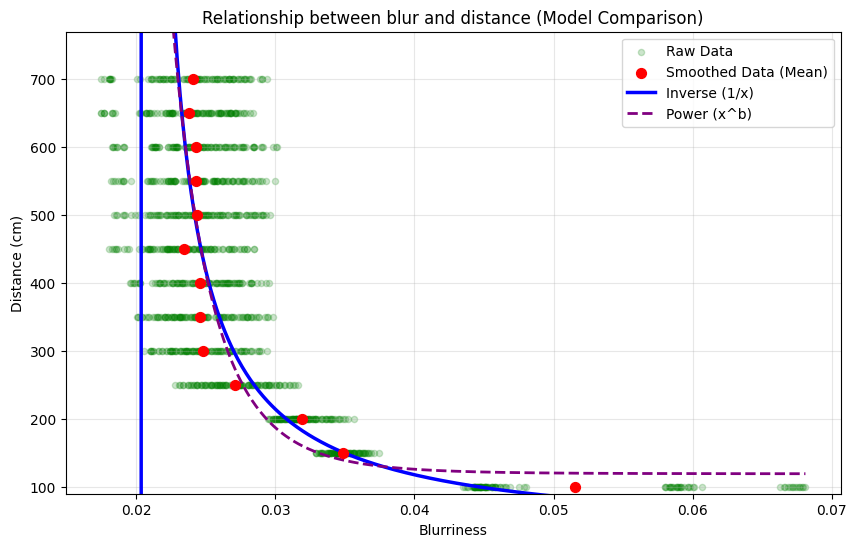

DIS100 : 0.008618924429483718
DIS150 : 0.0009870598300125062
DIS200 : 0.0014781761369833742
DIS250 : 0.002215704092887426
DIS300 : 0.002195463170985074
DIS350 : 0.002527511252807545
DIS400 : 0.002496347192874191
DIS450 : 0.0025280488523882257
DIS500 : 0.002858490954812008
DIS550 : 0.002777743071763259
DIS600 : 0.002932907279955647
DIS650 : 0.002808744157703366
DIS700 : 0.002921268765446693


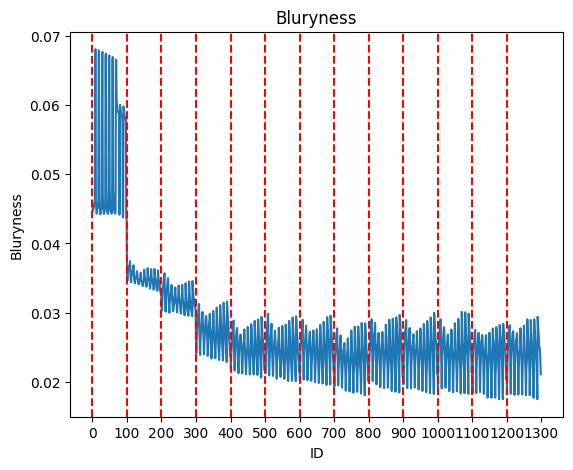

In [9]:
def path_tracker():
    compute()
    showing()
    sliding_window_sum()
    load_img()
    REC 
    JUMPER

def reset_result_file():
    for i in range(POSITION_START+1,POSITION_END+1):
        reset_txt(f"{RESULT}T{i}/-0.01.txt")

def get_shape():
    for i,imgs in enumerate(zip(R,L)):
        r = imgs[0]
        l = imgs[1]
        main(r[0],l[0],(POSITION_START+i+1))

def exp(size = 0):
    flag = 0  
    for i,data in enumerate(zip(R,L,MASK)):
        count = 0
        imagesR = data[0]
        imagesL = data[1]
        round_idx = POSITION_START+i+1
        times = len(imagesR)
        for g1 in imagesR:
            for g2 in imagesL:
                
                print("R = ",((count//times)+1)," L = ",((count%times)+1))
                flag  = main(g1,g2,0,data[2],round_idx,oblique=False,seg_size = size)
                count += 1
                # break
            # break
        if flag == -1: 
            break

def wrong_seg():
    for scalar in range(-2,3):
        # if scalar == 0:
        #     continue
        print("==----------------------------------------------==")
        print("SET : ",scalar)
        exp(scalar*1e-2)
        print("==----------------------------------------------==\n")

REC = False
REC2 = False     #convoluted blurness
REC3 = False   # #full size blurness

# CAL_HEAD = "./train/"
# POSITION_START = 12
# POSITION_END = 9
load_img()


# get_shape()
train()
#reset_result_file()
# exp()
#wrong_seg()



In [ ]:
"""
focal 7m f1.4 f22
[Inverse] a=728.80, b=0.2289, c=-2116.49 [728.80, 0.2289, -2116.49] 
[Power]   a=1772039.08, b=-0.0003, c=-1773068.42 [1772039.08, -0.0003, -1773068.42]

delete 1m 
[Inverse] a=4033.64, b=0.6121, c=-5590.19 [4033.64, 0.6121, -5590.19]
[Power]   a=1502160.51, b=-0.0003, c=-1503164.29 [1502160.51, -0.0003, -1503164.29]
"""

"""
focal 10m f1.4 f22
[Inverse] a=154.82, b=0.0465, c=-955.03 [154.82, 0.0465, -955.03]
[Power]   a=2268.99, b=-0.2032, c=-3521.65 [2268.99, -0.2032, -3521.65]

focal 10m f1.4 f22
[Inverse] a=612.77, b=0.1549, c=-2345.03 [612.77, 0.1549, -2345.03]
[Power]   a=1061311.95, b=-0.0008, c=-1063122.55 [1061311.95, -0.0008, -1063122.55]
"""

In [47]:
import cv2
import numpy as np
import os
import glob
import math

# ================= 參數設定區 =================
DATA_ROOT_DIR = 'D:\Carla-0.10.0-Win64-Shipping\Carla-0.10.0-Win64-Shipping\datas\Test_dataset_Focus1000cm_f1.4_f22'
MASK_ROOT_DIR = 'D:\Carla-0.10.0-Win64-Shipping\Carla-0.10.0-Win64-Shipping\datas\Test_dataset_Focus1000cm_f1.4_f22_mask'

# 真實距離 (Ground Truth) - 單位：公尺 (T1 ~ T13)
# GROUND_TRUTH = [1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0, 6.5, 7.0]
GROUND_TRUTH = [1.2, 1.7, 2.2, 2.7, 3.2, 3.7, 4.2, 4.7, 5.2, 5.7, 6.2, 6.7, 7.2]
# 影像參數
IMG_SIZE = (1536, 2048)
KER = 19
F = 4
D1 = F / 1.4   # Large Aperture
D2 = F / 22.0  # Small Aperture
FRACTION = (D1 / D2) ** 2
G_SELECT = 1   # 1: 使用 Large Image 計算 Laplacian

# ================= 模型參數 (更新) =================
# 1. 反比模型參數 (推薦)
PARAMS_INVERSE = [612.77, 0.1549, -2345.03]

# 2. 冪函數模型參數 (參考用)
PARAMS_POWER   = [1061311.95, -0.0008, -1063122.55]

# ================= 核心函式 =================

def inverse_model(x, a, b, c):
    """ 反比模型: y = a / (x + b) + c """
    if x + b == 0: return 0
    return a / (x + b) + c

def power_model(x, a, b, c):
    """ 冪函數模型: y = a * x^b + c """
    return a * np.power(x, b) + c

def get_first_image_in_folder(folder_path):
    extensions = ['*.jpg', '*.png', '*.bmp', '*.CR2']
    files = []
    for ext in extensions:
        files.extend(glob.glob(os.path.join(folder_path, ext)))
    files.sort()
    return files[0] if files else None

def compute_blur_value(img_small, img_large, mask):
    """ 
    計算 Mask 區域內的平均模糊度 (Blur Value)
    注意：這裡只負責算模糊度，不轉距離，方便套用不同模型
    """
    # 1. Resize
    img_s = cv2.resize(img_small, IMG_SIZE, interpolation=cv2.INTER_AREA)
    img_l = cv2.resize(img_large, IMG_SIZE, interpolation=cv2.INTER_AREA)
    mask  = cv2.resize(mask,      IMG_SIZE, interpolation=cv2.INTER_NEAREST)

    # 2. 轉灰階
    gray_s = cv2.cvtColor(img_s, cv2.COLOR_BGR2GRAY)
    gray_l = cv2.cvtColor(img_l, cv2.COLOR_BGR2GRAY)
    
    # 3. 亮度對齊 (以 Mask 區域為準，將 Large 調整至 Small 的亮度)
    mask_bool = (mask != 0)
    if np.sum(mask_bool) > 0:
        mean_s = np.mean(gray_s[mask_bool])
        mean_l = np.mean(gray_l[mask_bool])
        if mean_l != 0:
            gray_l = cv2.convertScaleAbs(gray_l, alpha=(mean_s / mean_l), beta=0)

    # 4. CLAHE
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(64, 64))
    gray_s = clahe.apply(gray_s)
    gray_l = clahe.apply(gray_l)

    # 5. DFD 演算法
    l = gray_l.astype(np.float64) # Large
    r = gray_s.astype(np.float64) # Small
    
    # 根據 G_SELECT 決定對誰做 Laplacian
    if G_SELECT == 1:
        # 對 Large (模糊圖) 做邊緣檢測
        lp = cv2.Laplacian(l, cv2.CV_64F, ksize=7, scale=2)
    else:
        lp = cv2.Laplacian(r, cv2.CV_64F, ksize=7, scale=2)
        
    sum_dif = cv2.boxFilter((l - r)**2, -1, (KER, KER), normalize=False)
    sum_lp  = cv2.boxFilter(lp**2,      -1, (KER, KER), normalize=False)

    with np.errstate(divide='ignore', invalid='ignore'):
        G = np.sqrt((16 * sum_dif) / sum_lp)
        param = (1 - (1.0 / FRACTION)) if G_SELECT == 1 else (FRACTION - 1)
        blurness_map = np.sqrt(G / param)

    blurness_map[~np.isfinite(blurness_map)] = 0

    if np.sum(mask_bool) == 0:
        return None

    # 回傳 Mask 區域內的平均模糊度
    return np.mean(blurness_map[mask_bool])

# ================= 主程式迴圈 =================

def main():
    print(f"{'ID':<4} | {'GT(m)':<6} | {'Blur':<8} | {'Inv(m)':<8} | {'Diff(m)':<8} | {'Pow(m)':<8} | {'Diff(m)':<8}")
    print("-" * 85)

    mse_inverse = []
    mse_power = []
    valid_count = 0

    # 迴圈讀取 T01 ~ T13
    for i in range(1, 14):
        folder_name = f"T{i:02d}"
        mask_name = f"T{i}.npy"
        
        # 取得 Ground Truth
        gt_m = GROUND_TRUTH[i-1] if (i-1 < len(GROUND_TRUTH)) else float('nan')

        # 路徑設定 (L=Small, R=Large)
        path_S = os.path.join(DATA_ROOT_DIR, folder_name, 'L') 
        path_L = os.path.join(DATA_ROOT_DIR, folder_name, 'R')
        path_mask = os.path.join(MASK_ROOT_DIR, mask_name)

        if not os.path.exists(path_S) or not os.path.exists(path_L) or not os.path.exists(path_mask):
            print(f"{folder_name:<4} | [Error] File missing")
            continue
        
        # 讀取圖片
        img_s = cv2.imread(get_first_image_in_folder(path_S)) # Small
        img_l = cv2.imread(get_first_image_in_folder(path_L)) # Large
        mask  = np.load(path_mask)

        # 1. 計算模糊度 (Blur Value)
        blur_val = compute_blur_value(img_small=img_s, img_large=img_l, mask=mask)

        if blur_val is not None:
            # 2. 套用模型計算距離 (輸出 cm 轉 m)
            dist_inv_m = inverse_model(blur_val, *PARAMS_INVERSE) / 100.0
            dist_pow_m = power_model(blur_val, *PARAMS_POWER)   / 100.0
            
            # 計算誤差
            diff_inv = dist_inv_m - gt_m
            diff_pow = dist_pow_m - gt_m
            
            mse_inverse.append(diff_inv ** 2)
            mse_power.append(diff_pow ** 2)
            valid_count += 1

            # 顯示結果
            print(f"{folder_name:<4} | {gt_m:<6.2f} | {blur_val:<8.5f} | "
                  f"{dist_inv_m:<8.4f} | {diff_inv:<8.4f} | "
                  f"{dist_pow_m:<8.4f} | {diff_pow:<8.4f}")
        else:
            print(f"{folder_name:<4} | Calculation Failed (Empty Mask or Error)")

    print("-" * 85)
    
    # 計算並顯示 RMSE
    if valid_count > 0:
        rmse_inv = np.sqrt(np.mean(mse_inverse))
        rmse_pow = np.sqrt(np.mean(mse_power))
        print(f"Total Samples: {valid_count}")
        print(f"RMSE [Inverse Model]: {rmse_inv:.4f} m  (推薦)")
        print(f"RMSE [Power Model]  : {rmse_pow:.4f} m")
    else:
        print("No valid data to calculate RMSE.")

if __name__ == "__main__":
    main()

ID   | GT(m)  | Blur     | Inv(m)   | Diff(m)  | Pow(m)   | Diff(m) 
-------------------------------------------------------------------------------------
T01  | 1.20   | 0.22978  | -7.5208  | -8.7208  | -5.6121  | -6.8121 
T02  | 1.70   | 0.23953  | -7.9147  | -9.6147  | -5.9655  | -7.6655 
T03  | 2.20   | 0.21296  | -6.7925  | -8.9925  | -4.9659  | -7.1659 
T04  | 2.70   | 0.19704  | -6.0393  | -8.7393  | -4.3057  | -7.0057 
T05  | 3.20   | 0.14750  | -3.1864  | -6.3864  | -1.8431  | -5.0431 
T06  | 3.70   | 0.12137  | -1.2704  | -4.9704  | -0.1853  | -3.8853 
T07  | 4.20   | 0.10594  | 0.0417   | -4.1583  | 0.9712   | -3.2288 
T08  | 4.70   | 0.09048  | 1.5223   | -3.1777  | 2.3134   | -2.3866 
T09  | 5.20   | 0.07842  | 2.8123   | -2.3877  | 3.5296   | -1.6704 
T10  | 5.70   | 0.06751  | 4.1011   | -1.5989  | 4.8047   | -0.8953 
T11  | 6.20   | 0.06158  | 4.8560   | -1.3440  | 5.5872   | -0.6128 
T12  | 6.70   | 0.05553  | 5.6694   | -1.0306  | 6.4668   | -0.2332 
T13  | [Error] Fi

=== 開始模糊度測距測試 ===
原始尺寸 - R: (1536, 2048, 3), L: (1536, 2048, 3), Mask: (1536, 2048)
[Info] Brightness Ratio (Alpha): 1.0168
處理後尺寸 - (2048, 1536)

=== 計算結果 ===
Mask 區域平均模糊度 (Blurness): 0.100774
預測距離 (Distance): 154.00 cm


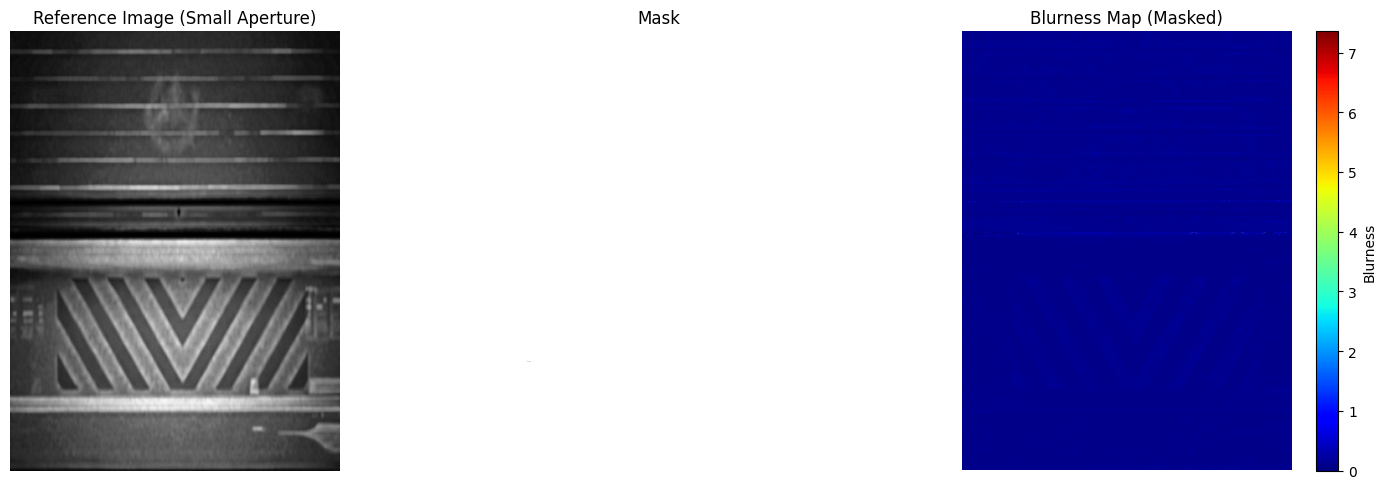

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ================= 參數設定區 =================
# 請將這裡換成你的圖片路徑
IMG_LARGE_PATH = '/home/e114/DFDS/datas/Test_dataset_Focus50cm_f4_f22/T01/R/D1.2_shot01.png'
IMG_SMALL_PATH = '/home/e114/DFDS/datas/Test_dataset_Focus50cm_f4_f22/T01/L/D1.2_shot01.png'
MASK_PATH      = '/home/e114/DFDS/datas/Test_dataset_Focus50cm_f4_f22_mask/T1.npy'

# 相機與演算法參數 (依照你的 Notebook 設定)
F = 4.0             # 焦距 cm
D1 = F / 4.0        # 大光圈直徑 (f/4)
D2 = F / 22.0       # 小光圈直徑 (f/22)
FRACTION = (D1 / D2) ** 2
IMG_SIZE = (1536, 2048)  # (Width, Height) -> OpenCV Resize 用
KER = 19            # 滑動視窗大小
G_SELECT = 1       # 1: 使用 Large Aperture 計算 Laplacian

# 訓練好的參數 (a, b, c, d)
MODEL_PARA = [58548842.89336719, -17672175.18318926, 1778393.29995472, -59512.70877175]

# ================= 核心函式 =================

def f(x, a, b, c, d):
    """ 模糊度 -> 距離轉換函式 (三次多項式) """
    return a * x**3 + b * x**2 + c * x + d

def preprocess_images(img_s, img_l, mask):
    """ 
    影像預處理：
    1. Resize (包含 Mask 的修正)
    2. 轉灰階
    3. 亮度對齊 (Brightness Matching)
    4. CLAHE
    """
    # 1. Resize (關鍵修正：Mask 使用 INTER_NEAREST)
    img_s = cv2.resize(img_s, IMG_SIZE, interpolation=cv2.INTER_AREA)
    img_l = cv2.resize(img_l, IMG_SIZE, interpolation=cv2.INTER_AREA)
    mask  = cv2.resize(mask,  IMG_SIZE, interpolation=cv2.INTER_NEAREST)

    # 2. 轉灰階
    gray_s = cv2.cvtColor(img_s, cv2.COLOR_BGR2GRAY)
    gray_l = cv2.cvtColor(img_l, cv2.COLOR_BGR2GRAY)

    # 3. 亮度對齊 (以 Mask 區域為基準，將 Large 調整至 Small 的亮度)
    # 找出 mask 區域的像素
    mask_bool = (mask != 0)
    
    if np.sum(mask_bool) > 0:
        mean_s = np.mean(gray_s[mask_bool])
        mean_l = np.mean(gray_l[mask_bool])
        
        if mean_l != 0:
            alpha = mean_s / mean_l
            # 調整大光圈圖片亮度
            gray_l = cv2.convertScaleAbs(gray_l, alpha=alpha, beta=0)
            print(f"[Info] Brightness Ratio (Alpha): {alpha:.4f}")

    # 4. CLAHE 增強
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(64, 64))
    gray_s = clahe.apply(gray_s)
    gray_l = clahe.apply(gray_l)

    return gray_s, gray_l, mask

def calculate_blurness_map(gray_s, gray_l):
    """ 計算模糊度圖 (Blurness Map) """
    # 轉為浮點數進行計算
    r = gray_s.astype(np.float64)
    l = gray_l.astype(np.float64)

    # 1. 計算 Laplacian (邊緣能量)
    # 根據 G_SELECT = 1，我們對 Large (l) 做 Laplacian
    k_size = 7
    scale = 2
    if G_SELECT == 1:
        lp = cv2.Laplacian(l, cv2.CV_64F, ksize=k_size, scale=scale)
    else:
        lp = cv2.Laplacian(r, cv2.CV_64F, ksize=k_size, scale=scale)
    
    lp_sq = lp ** 2

    # 2. 計算 Difference (差異能量)
    dif = l - r
    dif_sq = dif ** 2

    # 3. 滑動視窗加總 (Sliding Window Sum)
    # 使用 boxFilter 來模擬 sliding window sum，速度快很多
    sum_dif = cv2.boxFilter(dif_sq, -1, (KER, KER), normalize=False)
    sum_lp  = cv2.boxFilter(lp_sq,  -1, (KER, KER), normalize=False)

    # 4. 計算 G 值與模糊度
    # 避免除以 0
    with np.errstate(divide='ignore', invalid='ignore'):
        G = np.sqrt((16 * sum_dif) / sum_lp)
        
        # 參數計算 (參考你的 Notebook 邏輯)
        if G_SELECT == 2:
            param = FRACTION - 1
        else: # G_SELECT == 1
            param = 1 - (1.0 / FRACTION)
            
        blurness_map = np.sqrt(G / param)

    # 清理無效值 (NaN / Inf)
    blurness_map[~np.isfinite(blurness_map)] = 0

    return blurness_map

# ================= 主程式 =================
def main():
    print("=== 開始模糊度測距測試 ===")
    
    # 1. 讀取影像
    img_s = cv2.imread(IMG_SMALL_PATH)
    img_l = cv2.imread(IMG_LARGE_PATH)
    
    # 讀取 Mask (如果是 npy 就用 np.load，如果是圖片就用 imread)
    if MASK_PATH.endswith('.npy'):
        mask = np.load(MASK_PATH)
    else:
        mask = cv2.imread(MASK_PATH, cv2.IMREAD_GRAYSCALE)

    if img_s is None or img_l is None or mask is None:
        print("錯誤：找不到圖片或 Mask，請檢查路徑。")
        return

    print(f"原始尺寸 - R: {img_s.shape}, L: {img_l.shape}, Mask: {mask.shape}")

    # 2. 預處理 (含 Resize)
    r_proc, l_proc, mask_proc = preprocess_images(img_s, img_l, mask)
    print(f"處理後尺寸 - {r_proc.shape}")

    # 3. 計算全圖模糊度
    blur_map = calculate_blurness_map(r_proc, l_proc)

    # 4. 提取 Mask 區域的模糊度
    # 將 mask 二值化 (確保是 boolean)
    mask_bool = (mask_proc != 0)
    
    if np.sum(mask_bool) == 0:
        print("錯誤：Mask 區域為空！")
        return

    # 取出 mask 區域內的模糊度值
    valid_blurness = blur_map[mask_bool]
    
    # 計算平均模糊度 (去除極端值或是單純平均)
    mean_blurness = np.mean(valid_blurness)
    
    # 5. 計算距離
    pred_distance = f(mean_blurness, *MODEL_PARA)

    print("\n=== 計算結果 ===")
    print(f"Mask 區域平均模糊度 (Blurness): {mean_blurness:.6f}")
    print(f"預測距離 (Distance): {pred_distance:.2f} cm")

    # 6. 視覺化結果 (選用)
    plt.figure(figsize=(15, 5))
    
    plt.subplot(1, 3, 1)
    plt.title("Reference Image (Small Aperture)")
    plt.imshow(r_proc, cmap='gray')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.title("Mask")
    plt.imshow(mask_proc, cmap='gray')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.title("Blurness Map (Masked)")
    # 只顯示 mask 區域的模糊度，其他變黑
    show_blur = blur_map.copy()
    show_blur[~mask_bool] = 0
    plt.imshow(show_blur, cmap='jet', vmin=0, vmax=np.max(valid_blurness)*1.2)
    plt.colorbar(label='Blurness')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    main()